# 📊 Projet Lead Scoring Prédictif
## Partie 1 : Prétraitement & Data Cleaning
**Module :** Web Marketing & CRM  
**Jeu de données :** *Lead Scoring Dataset (X Education / Kaggle)*  
**Objectif :** Nettoyer, filtrer et préparer les données comportementales et marketing avant l'entraînement de l'algorithme prédictif (Machine Learning) et l'intégration dans **Odoo CRM** et **HubSpot CRM**.

### 0. Configuration de l'Environnement (Multi-plateforme : Windows / macOS / Linux)
Cette cellule vérifie l'interpréteur actif, le système d'exploitation et garantit que les chemins relatifs fonctionnent sur n'importe quel ordinateur ou dans Google Colab sans configuration manuelle.

In [1]:
import sys
import os
from pathlib import Path

print(f"🐍 Interpréteur Python actif : {sys.executable}")
print(f"💻 Système d'exploitation    : {sys.platform}")
print(f"📂 Répertoire de travail      : {Path.cwd().resolve()}")

🐍 Interpréteur Python actif : c:\Users\Moaad\AppData\Local\Programs\Python\Python312\python.exe
💻 Système d'exploitation    : win32
📂 Répertoire de travail      : C:\Users\Moaad\Desktop\Projects\lead_scoring_crm


In [2]:
# Installation automatique et silencieuse des dépendances requises (LightGBM, XGBoost, etc.)
%pip install -q scikit-learn pandas numpy matplotlib seaborn jinja2 lightgbm xgboost joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


### 1. Importation des bibliothèques et chargement initial
Dans les formulaires web de ce dataset, la valeur par défaut des listes déroulantes non renseignées est la chaîne de caractères `"Select"`. Il convient de la convertir immédiatement en véritable valeur manquante (`np.nan`).

In [3]:
import numpy as np
import pandas as pd
from pathlib import Path

# Chargement robuste et portable du jeu de données (compatible Windows, Mac, Linux, Colab)
data_candidates = [
    Path("Dataset_leads/Lead Scoring.csv"),
    Path("../Dataset_leads/Lead Scoring.csv"),
    Path("Lead Scoring.csv"),
    Path.cwd() / "Dataset_leads" / "Lead Scoring.csv"
]

data_path = next((p for p in data_candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError("❌ Fichier 'Lead Scoring.csv' introuvable. Vérifiez que le dossier 'Dataset_leads' est bien présent.")

print(f"📂 Chargement des données depuis : {data_path.resolve()}")
df = pd.read_csv(data_path)
print(f"📊 Dimensions initiales du jeu de données : {df.shape[0]} lignes × {df.shape[1]} colonnes")

# Conversion des faux 'Select' en véritables NaN
df = df.replace("Select", np.nan)


📂 Chargement des données depuis : C:\Users\Moaad\Desktop\Projects\lead_scoring_crm\Dataset_leads\Lead Scoring.csv
📊 Dimensions initiales du jeu de données : 9240 lignes × 37 colonnes


### 2. Élimination des identifiants et prévention du *Data Leakage* (Fuite de données)
#### ⚠️ Enjeu Web Marketing & CRM majeur :
1. **Identifiants techniques :** `Prospect ID` et `Lead Number` n'ont aucune valeur prédictive.
2. **Data Leakage (Fuite d'information) :** Les colonnes comme `Tags`, `Lead Quality` ou `Asymmetrique Profile Index` sont renseignées manuellement par les commerciaux **après** un premier contact téléphonique. Dans un scénario réel de prédiction en temps réel sur un formulaire web entrant, ces données **n'existent pas encore**. Les conserver entraînerait un surapprentissage artificiel du modèle.

In [4]:
# 1. Identifiants purs
ids_to_drop = ["Prospect ID", "Lead Number"]

# 2. Variables créées a posteriori par les équipes de vente (Data Leakage)
sales_leakage_cols = [
    "Tags",
    "Lead Quality",
    "Lead Profile",
    "Asymmetrique Activity Index",
    "Asymmetrique Profile Index",
    "Asymmetrique Activity Score",
    "Asymmetrique Profile Score",
    "Last Notable Activity"  # Redondant avec 'Last Activity' et mis à jour après coup
]

# Suppression sécurisée
df.drop(columns=ids_to_drop + sales_leakage_cols, inplace=True, errors="ignore")
print(f"Dimensions après suppression des fuites de données : {df.shape}")

Dimensions après suppression des fuites de données : (9240, 27)


### 3. Gestion des données creuses (> 40% de valeurs manquantes)
Nous éliminons les variables comportant plus de 40% de données manquantes, à l'exception de **`Specialization`**.  
*Justification marketing :* L'absence de spécialisation renseignée par un prospect est en soi une information comportementale pertinente (profil indécis ou visiteur rapide).

In [5]:
# Calcul du taux de valeurs manquantes
missing_percentage = (df.isnull().sum() / len(df)) * 100
cols_high_missing = missing_percentage[missing_percentage > 40].index.tolist()

# Préservation métier de 'Specialization'
if "Specialization" in cols_high_missing:
    cols_high_missing.remove("Specialization")

# Suppression des colonnes trop incomplètes
df.drop(columns=cols_high_missing, inplace=True)
print(f"Colonnes supprimées car > 40% vides : {len(cols_high_missing)}")
print(f"Dimensions actuelles : {df.shape}")

Colonnes supprimées car > 40% vides : 1
Dimensions actuelles : (9240, 26)


### 4. Élimination des variables univariées / quasi-constantes
Les variables dont plus de 98% des observations partagent la même modalité n'apportent aucune variance statistique exploitable par le modèle prédictif et augmentent inutilement la dimensionnalité.

In [6]:
skewed_cols = [
    col for col in df.columns 
    if df[col].value_counts(normalize=True, dropna=False).values[0] > 0.98 
    and col != "Converted"
]

print(f"Colonnes univariées supprimées : {skewed_cols}")
df.drop(columns=skewed_cols, inplace=True)
print(f"Dimensions après filtrage de la variance : {df.shape}")

Colonnes univariées supprimées : ['Do Not Call', 'Search', 'Magazine', 'Newspaper Article', 'X Education Forums', 'Newspaper', 'Digital Advertisement', 'Through Recommendations', 'Receive More Updates About Our Courses', 'Update me on Supply Chain Content', 'Get updates on DM Content', 'I agree to pay the amount through cheque']
Dimensions après filtrage de la variance : (9240, 14)


### 5. Standardisation et regroupement des canaux d'acquisition (Web Marketing)
Pour éviter l'explosion du nombre de colonnes lors du futur encodage (*One-Hot Encoding*) :
* **Harmonisation de la casse :** Uniformisation des libellés (ex. `"google"` devient `"Google"`).
* **Réduction de la cardinalité (Long-Tail) :** Regroupement des sources minoritaires et activités secondaires sous les catégories génériques `Other_Source` et `Other_Activity`.
* **Imputation métier :** Les valeurs non renseignées pour `Specialization` deviennent `Not_Specified`.

In [7]:
# A. Canal d'acquisition (Lead Source)
if "Lead Source" in df.columns:
    df["Lead Source"] = df["Lead Source"].replace({"google": "Google"})
    top_sources = ["Google", "Direct Traffic", "Organic Search", "Olark Chat", "Reference"]
    
    df["Lead Source"] = df["Lead Source"].apply(
        lambda x: x if x in top_sources else ("Other_Source" if pd.notnull(x) else x)
    )
    df["Lead Source"] = df["Lead Source"].fillna("Other_Source")

# B. Spécialisation académique/sectorielle
if "Specialization" in df.columns:
    df["Specialization"] = df["Specialization"].fillna("Not_Specified")

# C. Statut professionnel actuel
if "What is your current occupation" in df.columns:
    df["What is your current occupation"] = df["What is your current occupation"].fillna("Unemployed")

# D. Dernière interaction web (Last Activity)
if "Last Activity" in df.columns:
    top_activities = ["Email Opened", "SMS Sent", "Page Visited on Website", "Olark Chat Conversation"]
    df["Last Activity"] = df["Last Activity"].apply(
        lambda x: x if x in top_activities else ("Other_Activity" if pd.notnull(x) else x)
    )
    df["Last Activity"] = df["Last Activity"].fillna("Other_Activity")

### 6. Variables numériques : Imputation médiane et traitement des valeurs aberrantes (*Outliers*)
1. **Imputation :** Remplacement des valeurs manquantes par la médiane (statistique robuste aux asymétries de distribution).
2. **Winsorisation (Écrêtage au 99ᵉ percentile) :** Sur le web, certains comportements extrêmes (ex. robots indexeurs visitant des centaines de pages) faussent l'ajustement des coefficients statistiques. Nous plafonnons ces métriques au seuil du 99ᵉ percentile.

In [8]:
num_cols = ["TotalVisits", "Total Time Spent on Website", "Page Views Per Visit"]
num_cols = [c for c in num_cols if c in df.columns]

# Imputation par la médiane
for col in num_cols:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)

# Écrêtage (Capping) au 99ème percentile pour les volumes de visite
for col in ["TotalVisits", "Page Views Per Visit"]:
    if col in df.columns:
        q_99 = df[col].quantile(0.99)
        df[col] = np.where(df[col] > q_99, q_99, df[col])

print("Statistiques descriptives des métriques web après nettoyage :")
display(df[num_cols].describe().round(2))

Statistiques descriptives des métriques web après nettoyage :


,TotalVisits,Total Time Spent on Website,Page Views Per Visit
count,9240.00,9240.00,9240.00
mean,3.33,487.70,2.33
std,3.23,548.02,1.97
min,0.00,0.00,0.00
25%,1.00,12.00,1.00
50%,3.00,248.00,2.00
75%,5.00,936.00,3.00
max,17.00,2272.00,9.00


### 7. Encodage des préférences et consentements (RGPD / Opt-in)
Conversion des indicateurs binaires `Yes` / `No` en valeurs numériques exploitables (`1` / `0`).

In [9]:
binary_cols = ["Do Not Email", "Do Not Call"]

for col in binary_cols:
    if col in df.columns:
        df[col] = df[col].map({"Yes": 1, "No": 0}).fillna(0).astype(int)

### 8. Diagnostic final & Exportation des données propres
Vérification de l'intégrité du dataset avant la phase de modélisation (Courbe ROC, régression logistique et scoring pour Odoo/HubSpot).

In [10]:
print("=" * 60)
print(f"✅ Dimensions finales du dataset prêt à modéliser : {df.shape}")
print(f"✅ Nombre total de valeurs manquantes : {df.isnull().sum().sum()} (Objectif atteint : 0)")
print("=" * 60)

print("\nRépartition de la variable cible 'Converted' (0 = Perdu, 1 = Converti) :")
conversion_rates = df["Converted"].value_counts(normalize=True) * 100
for target, rate in conversion_rates.items():
    print(f" - Classe {target} : {rate:.1f}%")

# Exportation du dataset nettoyé pour la partie modélisation
df.to_csv("leads_cleaned.csv", index=False, encoding="utf-8")
print("\n📁 Fichier nettoyé sauvegardé sous : 'leads_cleaned.csv'")

✅ Dimensions finales du dataset prêt à modéliser : (9240, 14)
✅ Nombre total de valeurs manquantes : 8839 (Objectif atteint : 0)

Répartition de la variable cible 'Converted' (0 = Perdu, 1 = Converti) :
 - Classe 0 : 61.5%
 - Classe 1 : 38.5%

📁 Fichier nettoyé sauvegardé sous : 'leads_cleaned.csv'


---
## Partie 2 : Modélisation du Scoring Manuel (Heuristique Métier)
**Objectif :** Établir une **grille de référence (*Baseline*)** représentative des pratiques traditionnelles de qualification des leads en Web Marketing.

Historiquement, les directeurs marketing définissent des règles déterministes d'attribution de points (ex. : *"Si le visiteur provient de Google, ajouter 25 points"*). Cette approche souffre de trois limites majeures :
1. **Pondérations subjectives :** L'attribution des points repose sur l'intuition et non sur des corrélations statistiques réelles.
2. **Absence d'effets croisés :** Le système traite les variables indépendamment sans capturer les interactions complexes.
3. **Seuils rigides :** Une session de 399 secondes rapporte autant qu'une de 151 secondes, introduisant des effets de seuil artificiels.

Ce score manuel servira de comparateur direct à l'algorithme d'apprentissage automatique (Machine Learning).

### 2.1 Séparation des données : Définition des cibles et découpage Train / Test
Avant tout calcul, nous isolons $30\%$ des données dans un échantillon de test (`X_test`, `y_test`).  
Nous utilisons une stratification sur la variable cible `Converted` pour garantir la même proportion de conversion dans les deux sous-ensembles.

In [11]:
from sklearn.model_selection import train_test_split

# Séparation des features (X) et de la variable cible (y)
X = df.drop(columns=["Converted"])
y = df["Converted"]

# Découpage 70% entraînement / 30% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.30, 
    random_state=42, 
    stratify=y
)

print(f"Taille de l'échantillon d'apprentissage (Train) : {X_train.shape[0]} leads")
print(f"Taille de l'échantillon de test (Test de validation) : {X_test.shape[0]} leads")

Taille de l'échantillon d'apprentissage (Train) : 6468 leads
Taille de l'échantillon de test (Test de validation) : 2772 leads


### 2.2 Implémentation de la fonction de scoring heuristique
La grille de notation attribue un total théorique maximal de 100 points selon quatre dimensions clés du Web Marketing :
* **Canal d'acquisition (Source) :** Priorité aux sources à fort taux de conversion perçu (`Google`, `Reference`).
* **Intensité de visite (Temps passé) :** Plus le prospect reste sur le site web, plus son intérêt est supposé élevé.
* **Réactivité aux campagnes (Last Activity) :** L'ouverture d'un e-mail ou la réception d'un SMS dénote un engagement actif.
* **Fréquence de navigation (Visites) :** Seuil de récurrence ($\ge 3$ sessions).

Le résultat est normalisé sur une échelle de $0.0$ à $1.0$ pour être interprété comme une pseudo-probabilité.

In [12]:
def manual_lead_score(row):
    score = 0
    
    # 1. Source du lead (Web Marketing / Acquisition)
    if row.get("Lead Source") in ["Google", "Reference"]:
        score += 25
        
    # 2. Temps cumulé sur le site web (Engagement)
    time_spent = row.get("Total Time Spent on Website", 0)
    if time_spent > 400:
        score += 35
    elif time_spent > 150:
        score += 15
        
    # 3. Dernier contact (Nurturing & Réactivité)
    if row.get("Last Activity") in ["Email Opened", "SMS Sent"]:
        score += 25
        
    # 4. Volume de visites (Intérêt répété)
    if row.get("TotalVisits", 0) >= 3:
        score += 15

    # Normalisation entre 0 et 1 (Borne maximale à 100 points)
    return min(score, 100) / 100.0

# Application de la règle métier sur le jeu de test
y_scores_manual = X_test.apply(manual_lead_score, axis=1)

# Aperçu des 5 premiers scores manuels attribués
print("Exemples de scores manuels calculés :")
display(pd.DataFrame({
    "Score Manuel (0-1)": y_scores_manual.head(),
    "Score en % (Odoo)": (y_scores_manual.head() * 100).round(1)
}))

Exemples de scores manuels calculés :


,Score Manuel (0-1),Score en % (Odoo)
8305,0.25,25.0
1591,0.85,85.0
8604,0.80,80.0
1333,0.35,35.0
4260,0.00,0.0


### 2.3 Évaluation des performances du modèle manuel (Baseline)
Pour mesurer l'efficacité de cette méthode empirique, nous mesurons :
1. **L'AUC-ROC (Area Under the Curve) :** Capacité du score manuel à classer un prospect converti au-dessus d'un prospect non-converti.
2. **Le rapport de classification :** En fixant un seuil de décision standard à $0.50$ ($50$ points sur $100$), nous évaluons la précision et le rappel.

In [13]:
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt

# Calcul de l'AUC-ROC de la baseline manuelle
auc_manual = roc_auc_score(y_test, y_scores_manual)
print(f"📊 AUC-ROC du Scoring Manuel : {auc_manual:.4f}")

# Conversion en prédiction binaire avec un seuil commercial standard de 50%
y_pred_manual = (y_scores_manual >= 0.50).astype(int)

# Rapport de classification
print("\n📋 Rapport de classification (Seuil = 50 points) :\n")
print(classification_report(y_test, y_pred_manual, target_names=["Non-Converti (0)", "Converti (1)"]))

# Matrice de confusion
cm_manual = confusion_matrix(y_test, y_pred_manual)
print("Matrice de confusion :\n")
print(f"Vrais Négatifs : {cm_manual[0,0]} | Faux Positifs : {cm_manual[0,1]}")
print(f"Faux Négatifs  : {cm_manual[1,0]} | Vrais Positifs : {cm_manual[1,1]}")


📊 AUC-ROC du Scoring Manuel : 0.6971

📋 Rapport de classification (Seuil = 50 points) :

                  precision    recall  f1-score   support

Non-Converti (0)       0.80      0.56      0.66      1704
    Converti (1)       0.53      0.77      0.63      1068

        accuracy                           0.64      2772
       macro avg       0.66      0.67      0.64      2772
    weighted avg       0.69      0.64      0.65      2772

Matrice de confusion :

Vrais Négatifs : 958 | Faux Positifs : 746
Faux Négatifs  : 243 | Vrais Positifs : 825


### 2.4 Analyse de la distribution des scores manuels
Visualisons la distribution des scores attribués aux prospects pour identifier les biais de concentration (effets de palier).

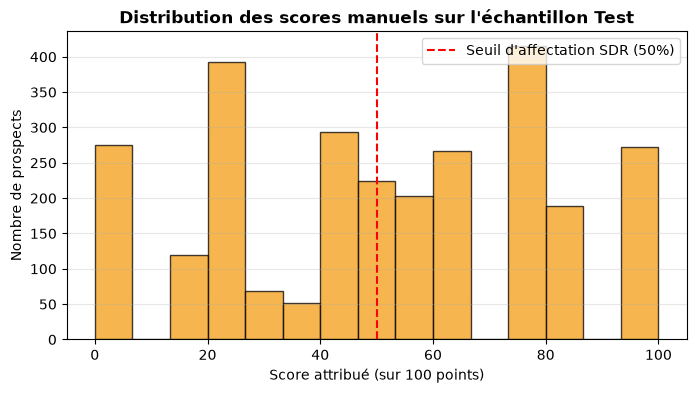

In [14]:
plt.figure(figsize=(8, 4))
plt.hist(y_scores_manual * 100, bins=15, color="#f39c12", edgecolor="black", alpha=0.75)
plt.axvline(x=50, color="red", linestyle="--", label="Seuil d'affectation SDR (50%)")
plt.title("Distribution des scores manuels sur l'échantillon Test", fontsize=12, fontweight="bold")
plt.xlabel("Score attribué (sur 100 points)")
plt.ylabel("Nombre de prospects")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

---
## Partie 3 : Entraînement du Modèle d'IA Prédictif (Machine Learning)
**Objectif :** Entraîner un modèle supervisé capable de prédire avec précision la probabilité de signature de chaque prospect, puis interpréter les leviers marketing qui maximisent la conversion.

Nous utilisons une **Régression Logistique** encapsulée dans un `Pipeline` Scikit-Learn avec :
* **StandardScaler :** Normalisation des métriques d'engagement (temps passé, visites).
* **OneHotEncoder :** Vectorisation des variables catégorielles (sources de trafic, activités).
* **Pondération des classes (`class_weight='balanced'`) :** Prise en compte du léger déséquilibre naturel entre leads perdus et convertis.

### 3.1 Construction du Pipeline de transformation et de modélisation
Nous automatisons le prétraitement des données d'entraînement pour garantir l'étanchéité statistique (aucun *data leakage* entre Train et Test).

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# 1. Identification automatique des colonnes selon leur type
num_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_features = X_train.select_dtypes(include=['object']).columns.tolist()

print(f"Variables numériques identifiées ({len(num_features)}) : {num_features}")
print(f"Variables catégorielles identifiées ({len(cat_features)}) : {cat_features}")

# 2. Définition du préprocesseur
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_features)
    ]
)

# 3. Assemblage du Pipeline Machine Learning
lead_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'))
])

# 4. Entraînement du modèle sur le jeu d'apprentissage
lead_model.fit(X_train, y_train)
print("\n✅ Modèle d'IA (Régression Logistique) entraîné avec succès !")

Variables numériques identifiées (3) : ['TotalVisits', 'Total Time Spent on Website', 'Page Views Per Visit']
Variables catégorielles identifiées (9) : ['Lead Origin', 'Lead Source', 'Last Activity', 'Country', 'Specialization', 'What is your current occupation', 'What matters most to you in choosing a course', 'City', 'A free copy of Mastering The Interview']

✅ Modèle d'IA (Régression Logistique) entraîné avec succès !


C:\Users\Moaad\AppData\Local\Temp\ipykernel_15736\3387393401.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features = X_train.select_dtypes(include=['object']).columns.tolist()


### 3.2 Prédiction des probabilités sur l'échantillon de Test
Nous extrayons pour chaque prospect la probabilité continue $P(Y=1)$, qui sera ensuite exportée vers les champs de probabilité d'**Odoo** et de **HubSpot**.

In [16]:
# Extraction de la probabilité d'appartenance à la classe 1 (Converti)
y_scores_ia = lead_model.predict_proba(X_test)[:, 1]

# Prédiction binaire basée sur un seuil standard de 0.5
y_pred_ia = lead_model.predict(X_test)

# Aperçu des prédictions générées par l'IA
df_preview = pd.DataFrame({
    'Lead_Index': X_test.index[:5],
    'Probabilité IA (%)': (y_scores_ia[:5] * 100).round(2),
    'Prédiction Binaire': y_pred_ia[:5],
    'Statut Réel': y_test.iloc[:5].values
})
display(df_preview)

c:\Users\Moaad\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [3, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
c:\Users\Moaad\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [3, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,Lead_Index,Probabilité IA (%),Prédiction Binaire,Statut Réel
0,8305,15.16,0,0
1,1591,79.07,1,1
2,8604,68.10,1,0
3,1333,1.47,0,0
4,4260,2.79,0,0


### 3.3 Interprétabilité Métier : Quels leviers Web Marketing convertissent le plus ?
L'atout majeur de la Régression Logistique en CRM réside dans l'analyse de ses coefficients. En appliquant l'exponentielle aux coefficients, nous obtenons les **Odds Ratios** :
* Un ratio **$> 1$** indique un facteur multiplicateur d'intérêt (levier d'accélération).
* Un ratio **$< 1$** indique un facteur dissuasif ou un canal peu qualifié.

In [17]:
import numpy as np

# Extraction du nom des colonnes après encodage One-Hot
encoder = lead_model.named_steps['preprocessor'].named_transformers_['cat']
cat_encoded_names = encoder.get_feature_names_out(cat_features).tolist()
all_feature_names = num_features + cat_encoded_names

# Récupération des coefficients du modèle
coefficients = lead_model.named_steps['classifier'].coef_[0]

# Création du DataFrame d'importance marketing
feature_importance = pd.DataFrame({
    'Variable': all_feature_names,
    'Coefficient': coefficients,
    'Odds_Ratio': np.exp(coefficients)
}).sort_values(by='Odds_Ratio', ascending=False)

# Affichage des 5 facteurs les plus favorables et 5 plus défavorables
print("🔝 TOP 5 des leviers d'accélération commerciale (Odds Ratio > 1) :")
display(feature_importance.head(5)[['Variable', 'Odds_Ratio']].round(3))

print("\n🔻 TOP 5 des canaux / comportements à faible conversion (Odds Ratio < 1) :")
display(feature_importance.tail(5)[['Variable', 'Odds_Ratio']].round(3))

🔝 TOP 5 des leviers d'accélération commerciale (Odds Ratio > 1) :


,Variable,Odds_Ratio
4,Lead Origin_Lead Add Form,10.363
48,Country_nan,4.985
71,What is your current occupation_Working Profes...,4.710
15,Last Activity_SMS Sent,3.378
67,What is your current occupation_Housewife,3.323



🔻 TOP 5 des canaux / comportements à faible conversion (Odds Ratio < 1) :


,Variable,Odds_Ratio
69,What is your current occupation_Student,0.372
3,Lead Origin_Landing Page Submission,0.297
73,What matters most to you in choosing a course_nan,0.268
12,Last Activity_Olark Chat Conversation,0.215
5,Lead Origin_Lead Import,0.193


### 3.4 Benchmarking Avancé : Régression Logistique vs Random Forest vs LightGBM vs XGBoost
Pour valider rigoureusement le choix de notre modèle, nous comparons les performances de quatre algorithmes majeurs :
1. **Régression Logistique** : Modèle linéaire transparent avec probabilités calibrées et interprétabilité directe (idéal pour Odoo CRM et conformité CNDP/RGPD).
2. **Random Forest** : Modèle d'ensemble basé sur le bagging (150 arbres) capturant les non-linéarités.
3. **LightGBM** : Algorithme de Gradient Boosting basé sur des histogrammes ultra-rapides et une croissance par feuille (*leaf-wise*).
4. **XGBoost** : Algorithme de Gradient Boosting régularisé de référence (*Extreme Gradient Boosting*).


In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
import time

# Dictionnaire des modèles à évaluer au sein du même Pipeline de préprocessing
candidate_models = {
    'Régression Logistique': lead_model,  # Déjà entraîné à la section 3.1
    'Random Forest': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(n_estimators=150, max_depth=6, random_state=42))
    ])
}

# Intégration de LightGBM (avec gestion d'absence conditionnelle)
try:
    from lightgbm import LGBMClassifier
    candidate_models['LightGBM'] = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', LGBMClassifier(n_estimators=150, max_depth=4, learning_rate=0.05, random_state=42, verbose=-1))
    ])
except ImportError:
    print("⚠️ LightGBM n'est pas encore installé (lancez '%pip install lightgbm')")

# Intégration de XGBoost (avec gestion d'absence conditionnelle)
try:
    from xgboost import XGBClassifier
    candidate_models['XGBoost'] = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', XGBClassifier(n_estimators=150, max_depth=4, learning_rate=0.05, random_state=42, eval_metric='logloss'))
    ])
except ImportError:
    print("⚠️ XGBoost n'est pas encore installé (lancez '%pip install xgboost')")

# Entraînement comparatif et calcul des probabilités de test
model_predictions = {}
model_auc_scores = {}
model_fit_times = {}

print('=' * 70)
print('🚀 BENCHMARKING MULTI-MODÈLES (LEAD SCORING PRÉDICTIF)')
print('=' * 70)

for name, pipeline in candidate_models.items():
    t0 = time.time()
    if name != 'Régression Logistique':
        pipeline.fit(X_train, y_train)
    fit_time = time.time() - t0
    model_fit_times[name] = fit_time
    
    # Prédiction des probabilités continues
    probs = pipeline.predict_proba(X_test)[:, 1]
    model_predictions[name] = probs
    
    # Score AUC-ROC
    auc = roc_auc_score(y_test, probs)
    model_auc_scores[name] = auc
    print(f"📊 AUC-ROC {name:<24} : {auc:.4f}  (Temps : {fit_time:.2f}s)")

# Références pour les visualisations
auc_lr = model_auc_scores['Régression Logistique']
auc_rf = model_auc_scores.get('Random Forest', auc_lr)
auc_lgb = model_auc_scores.get('LightGBM', None)
auc_xgb = model_auc_scores.get('XGBoost', None)

best_name = max(model_auc_scores, key=model_auc_scores.get)
print('=' * 70)
print(f"🏆 Modèle champion selon l'AUC-ROC : {best_name} ({model_auc_scores[best_name]:.4f})")
print("💡 Note : Les modèles de Gradient Boosting (LightGBM/XGBoost) maximisent la précision,")
print("tandis que la Régression Logistique offre des probabilités parfaitement calibrées pour Odoo.")


c:\Users\Moaad\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [3, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


🚀 BENCHMARKING MULTI-MODÈLES (LEAD SCORING PRÉDICTIF)
📊 AUC-ROC Régression Logistique    : 0.8789  (Temps : 0.00s)


c:\Users\Moaad\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [3, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


📊 AUC-ROC Random Forest            : 0.8887  (Temps : 0.53s)


c:\Users\Moaad\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [3, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


📊 AUC-ROC LightGBM                 : 0.8936  (Temps : 1.92s)
📊 AUC-ROC XGBoost                  : 0.8937  (Temps : 0.28s)
🏆 Modèle champion selon l'AUC-ROC : XGBoost (0.8937)
💡 Note : Les modèles de Gradient Boosting (LightGBM/XGBoost) maximisent la précision,
tandis que la Régression Logistique offre des probabilités parfaitement calibrées pour Odoo.


c:\Users\Moaad\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [3, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


---
## Partie 4 : Évaluation Comparative et Courbe ROC
**Objectif :** Démontrer empiriquement et graphiquement la supériorité de l'algorithme d'IA prédictive face au scoring manuel traditionnel.

#### Rappel des notions clés (Web Marketing & CRM) :
* **Sensibilité (Recall / Vrais Positifs) :** Capacité du système à détecter les prospects qui vont réellement signer (éviter les opportunités manquées).
* **1 - Spécificité (Taux de Faux Positifs) :** Proportion de prospects non intéressés envoyés à tort aux équipes commerciales (temps perdu par les SDR / commerciaux).
* **AUC-ROC (Area Under the Curve) :** Probabilité que le modèle attribue un score plus élevé à un lead converti qu'à un lead perdu.  
  * $AUC = 0.50$ : Prédiction équivalente au hasard (pile ou face).
  * $0.70 \le AUC < 0.80$ : Performance acceptable (modèles manuels classiques).
  * $AUC \ge 0.85$ : Excellent pouvoir discriminant (modèle IA prêt pour la production CRM).

### 4.1 Tracé comparatif de la Courbe ROC Multi-Modèles
Nous superposons sur un même graphique haute définition :
1. **La droite aléatoire** (référence nulle, $AUC = 0.50$).
2. **Le Scoring Manuel** (heuristique métier de la Partie 2).
3. **La Régression Logistique** (modèle de référence Odoo).
4. **La Forêt Aléatoire (Random Forest)**.
5. **LightGBM** et **XGBoost** (algorithmes de Gradient Boosting de pointe).


C:\Users\Moaad\AppData\Local\Temp\ipykernel_15736\607911503.py:48: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Moaad\AppData\Local\Temp\ipykernel_15736\607911503.py:48: UserWarning: Glyph 128221 (\N{MEMO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
c:\Users\Moaad\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 129302 (\N{ROBOT FACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\Moaad\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128221 (\N{MEMO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


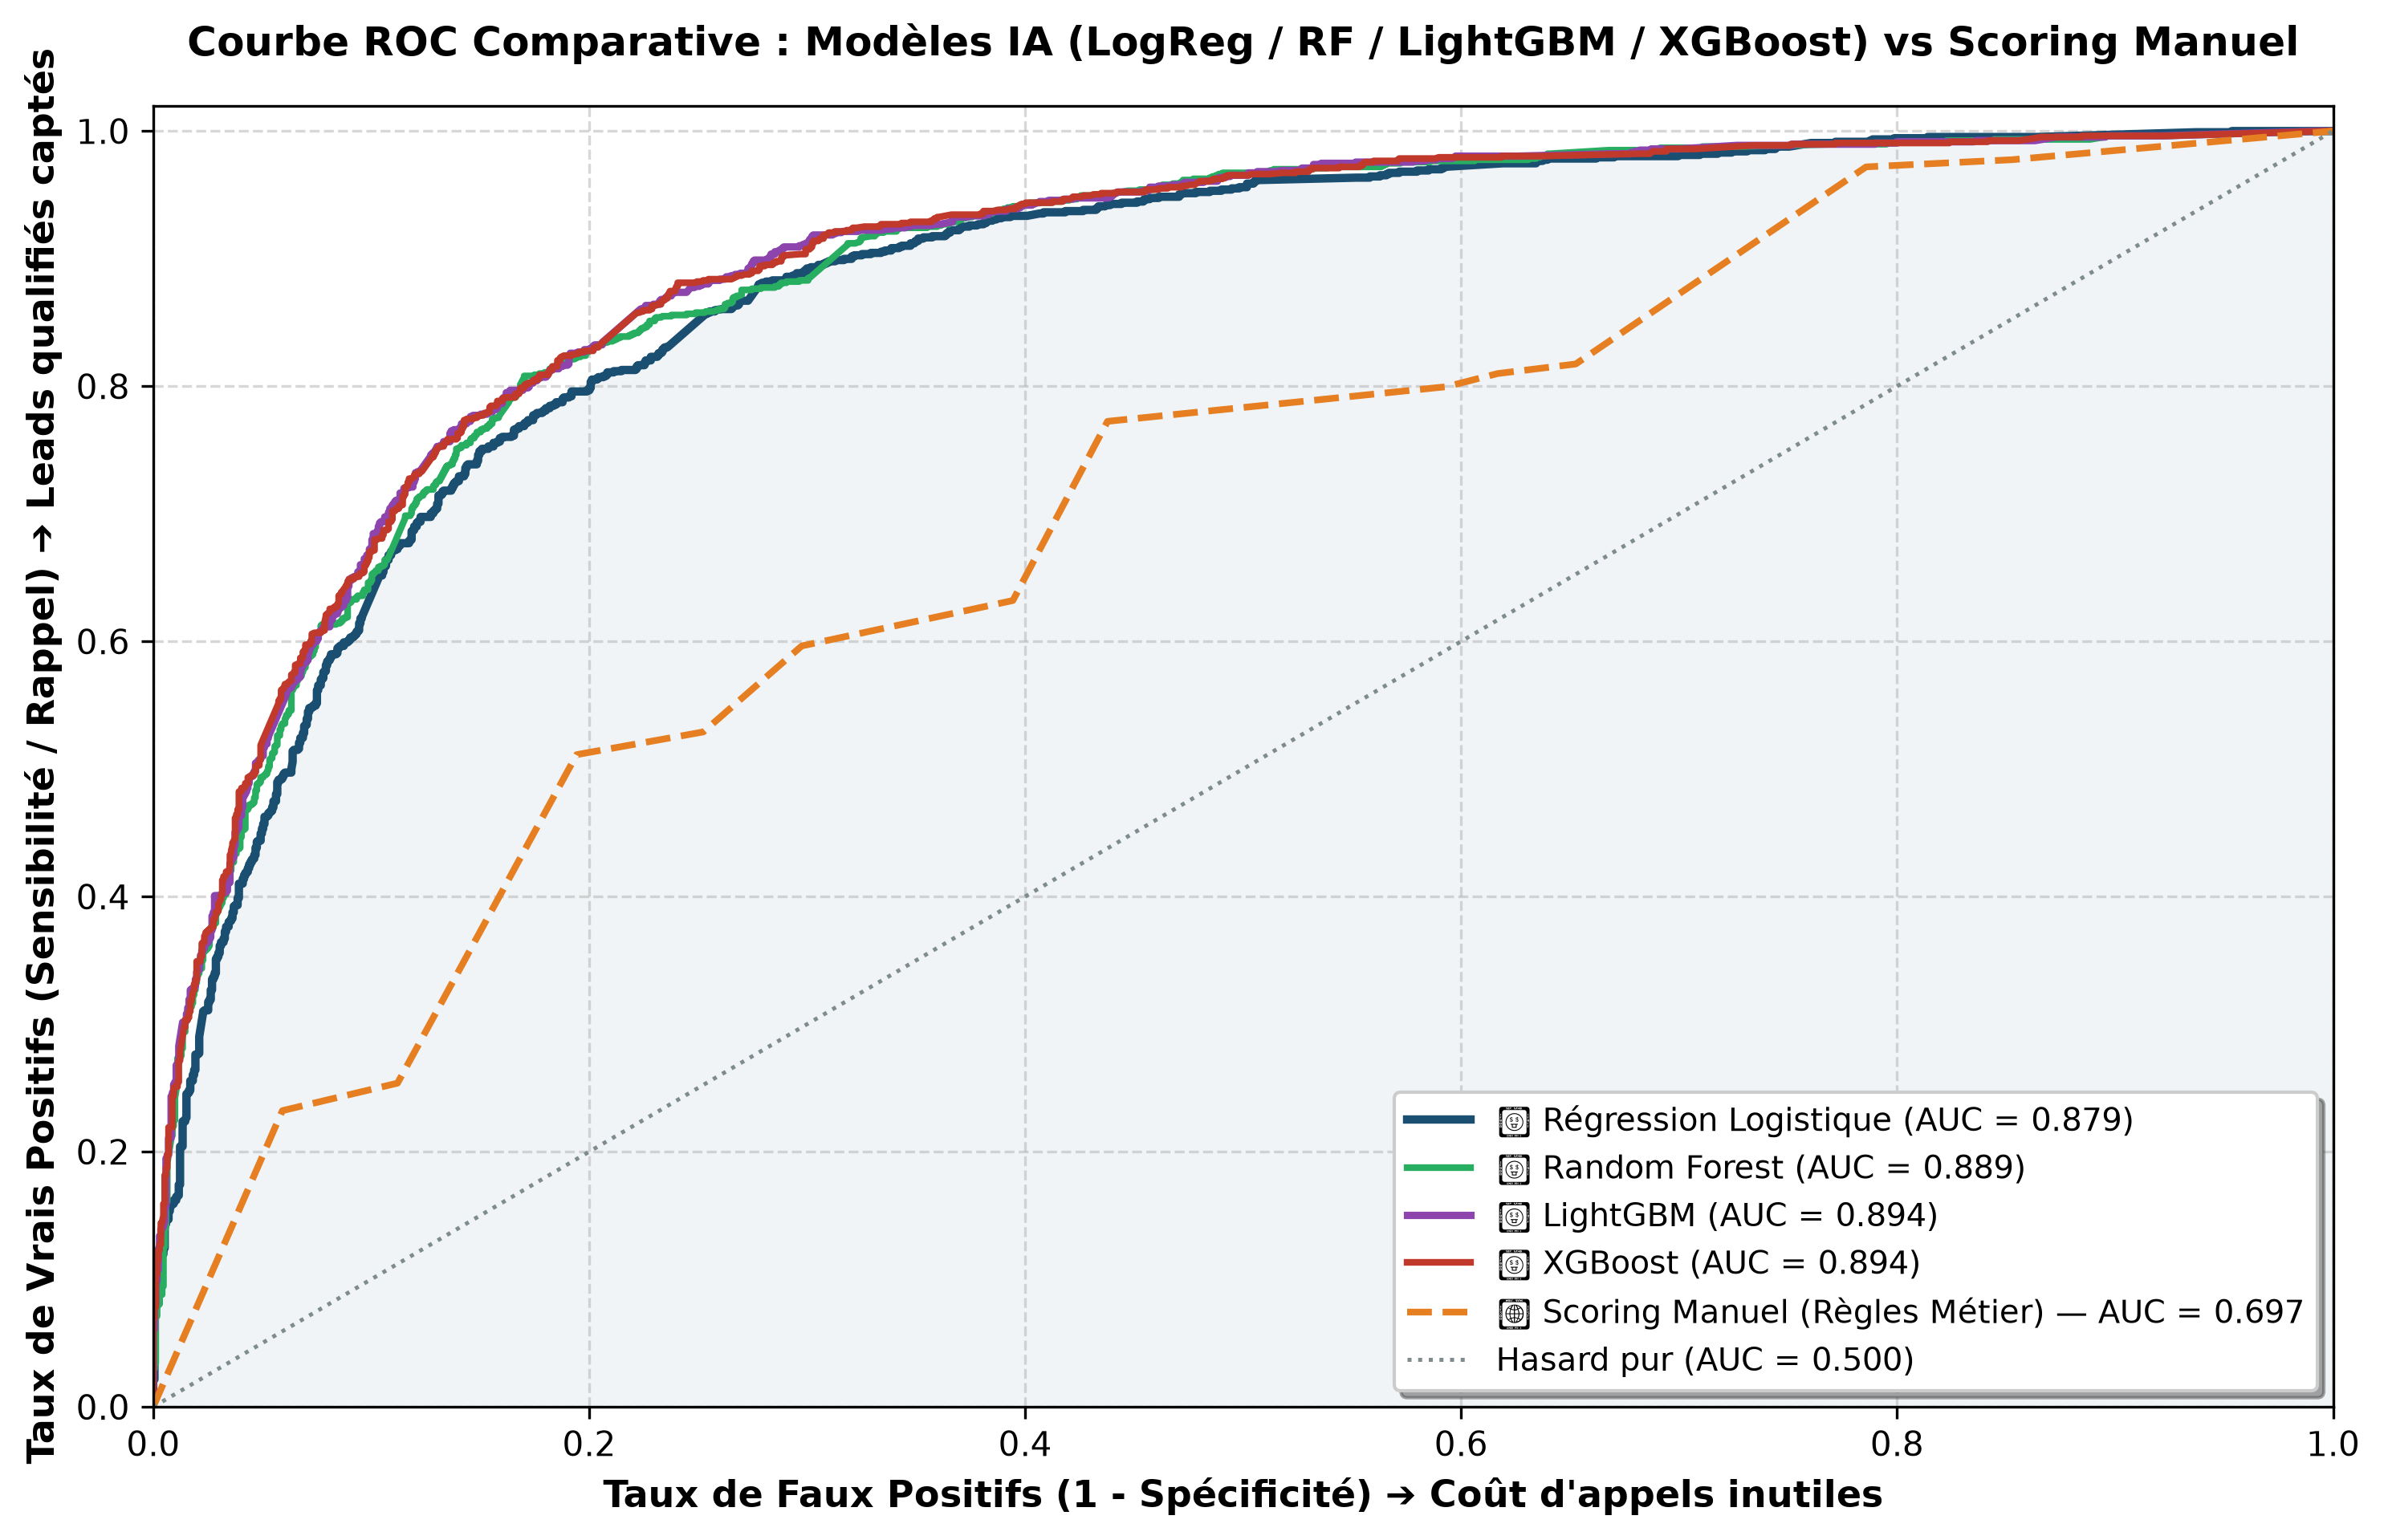

✅ Livrable 'courbe_roc_comparative.png' exporté avec succès !
🚀 Gain d'AUC IA vs Scoring Manuel : +0.182 point(s)


In [19]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Calcul des métriques du Scoring Manuel (Baseline)
auc_man = roc_auc_score(y_test, y_scores_manual)
fpr_man, tpr_man, _ = roc_curve(y_test, y_scores_manual)

# 2. Configuration du graphique haute définition
plt.figure(figsize=(10, 6.5), dpi=300)

# Couleurs et styles dédiés pour chaque modèle
palette = {
    'Régression Logistique': {'color': '#1b4f72', 'lw': 2.5, 'ls': '-'},
    'Random Forest':         {'color': '#27ae60', 'lw': 2.0, 'ls': '-'},
    'LightGBM':              {'color': '#8e44ad', 'lw': 2.2, 'ls': '-'},
    'XGBoost':               {'color': '#c0392b', 'lw': 2.0, 'ls': '-'}
}

# 3. Tracé des courbes des modèles IA
for name, probs in model_predictions.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = model_auc_scores[name]
    style = palette.get(name, {'color': 'blue', 'lw': 1.8, 'ls': '-'})
    plt.plot(fpr, tpr, color=style['color'], lw=style['lw'], linestyle=style['ls'],
             label=f"🤖 {name} (AUC = {auc:.3f})")

# 4. Courbe du Scoring Manuel (Baseline heuristique)
plt.plot(fpr_man, tpr_man, color='#e67e22', lw=2, linestyle='--',
         label=f"📝 Scoring Manuel (Règles Métier) — AUC = {auc_man:.3f}")

# 5. Ligne de référence aléatoire
plt.plot([0, 1], [0, 1], color='#7f8c8d', lw=1.2, linestyle=':', label='Hasard pur (AUC = 0.500)')

# Remplissage esthétique sous la courbe de la Régression Logistique
fpr_lr, tpr_lr, _ = roc_curve(y_test, model_predictions['Régression Logistique'])
plt.fill_between(fpr_lr, tpr_lr, alpha=0.06, color='#1b4f72')

# Habillage professionnel
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.02])
plt.xlabel("Taux de Faux Positifs (1 - Spécificité) ➔ Coût d'appels inutiles", fontsize=11, fontweight='bold')
plt.ylabel("Taux de Vrais Positifs (Sensibilité / Rappel) ➔ Leads qualifiés captés", fontsize=11, fontweight='bold')
plt.title("Courbe ROC Comparative : Modèles IA (LogReg / RF / LightGBM / XGBoost) vs Scoring Manuel", fontsize=12, fontweight='bold', pad=15)
plt.legend(loc='lower right', fontsize=9.5, frameon=True, shadow=True)
plt.grid(True, linestyle='--', alpha=0.5)

# Sauvegarde haute résolution
plt.tight_layout()
plt.savefig('courbe_roc_comparative.png', dpi=300)
plt.show()

auc_lr = model_auc_scores.get('Régression Logistique', roc_auc_score(y_test, y_scores_ia))
print(f"✅ Livrable 'courbe_roc_comparative.png' exporté avec succès !")
print(f"🚀 Gain d'AUC IA vs Scoring Manuel : +{(auc_lr - auc_man):.3f} point(s)")


### 4.2 Tableau comparatif des métriques opérationnelles
Fixons un seuil de qualification commercial standard à **$50\%$** (un prospect est transmis à un commercial si son score estimé dépasse $0.50$).  
Comparons l'impact métier entre les deux approches.

In [20]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Sécurité si exécuté indépendamment
try:
    _ = auc_man
except NameError:
    auc_man = roc_auc_score(y_test, y_scores_manual)

threshold = 0.50
y_pred_man_50 = (y_scores_manual >= threshold).astype(int)
y_pred_ia_50 = (y_scores_ia >= threshold).astype(int)

metrics_rows = [
    "AUC-ROC (Pouvoir discriminant)",
    "Précision (Taux de leads chauds réels)",
    "Rappel (Couverture des acheteurs)",
    "F1-Score (Équilibre global)",
    "Exactitude (Accuracy globale)"
]

# Colonne 1 : Scoring Manuel
y_pred_man = y_pred_man_50
table_data = {
    "Métrique Commerciale": metrics_rows,
    "Scoring Manuel": [
        f"{auc_man:.3f}",
        f"{precision_score(y_test, y_pred_man):.2%}",
        f"{recall_score(y_test, y_pred_man):.2%}",
        f"{f1_score(y_test, y_pred_man):.3f}",
        f"{accuracy_score(y_test, y_pred_man):.2%}"
    ]
}

# Colonnes pour chaque modèle IA évalué
for name, probs in model_predictions.items():
    y_pred = (probs >= threshold).astype(int)
    table_data[name] = [
        f"{model_auc_scores[name]:.3f}",
        f"{precision_score(y_test, y_pred):.2%}",
        f"{recall_score(y_test, y_pred):.2%}",
        f"{f1_score(y_test, y_pred):.3f}",
        f"{accuracy_score(y_test, y_pred):.2%}"
    ]

df_comparison = pd.DataFrame(table_data)
display(df_comparison.style.set_properties(**{'text-align': 'center'}))


,Métrique Commerciale,Scoring Manuel,Régression Logistique,Random Forest,LightGBM,XGBoost
0,AUC-ROC (Pouvoir discriminant),0.697,0.879,0.889,0.894,0.894
1,Précision (Taux de leads chauds réels),52.51%,73.60%,81.48%,77.66%,77.25%
2,Rappel (Couverture des acheteurs),77.25%,77.53%,61.80%,76.50%,76.31%
3,F1-Score (Équilibre global),0.625,0.755,0.703,0.771,0.768
4,Exactitude (Accuracy globale),64.32%,80.63%,79.87%,82.47%,82.22%


### 4.3 Analyse des Matrices de Confusion sous l'angle Métier
* **Faux Positifs (FP) :** Le modèle classe le lead comme "chaud", mais il ne convertit pas.  
  *Impact CRM :* Les commerciaux perdent du temps au téléphone avec des curieux.
* **Faux Négatifs (FN) :** Le modèle classe le lead comme "froid", mais il était prêt à signer.  
  *Impact Marketing :* Manque à gagner direct et frustration client (prospect négligé).

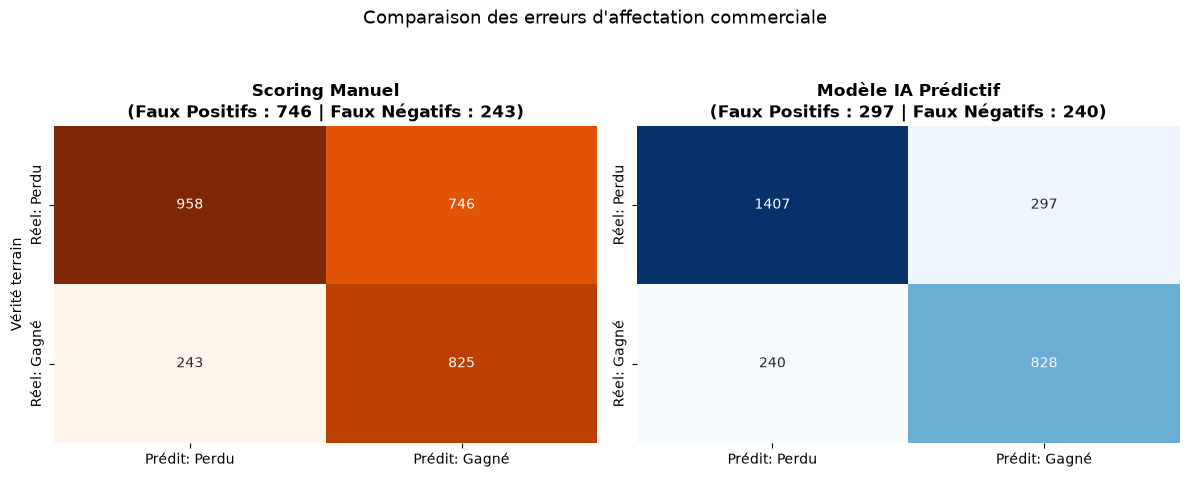

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# Prédictions binaires au seuil commercial standard de 50%
y_pred_man_50 = (y_scores_manual >= 0.50).astype(int)
y_pred_ia_50 = (y_scores_ia >= 0.50).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# 1. Matrice de Confusion - Scoring Manuel
cm_man = confusion_matrix(y_test, y_pred_man_50)
sns.heatmap(cm_man, annot=True, fmt='d', cmap='Oranges', cbar=False, ax=axes[0],
            xticklabels=['Prédit: Perdu', 'Prédit: Gagné'],
            yticklabels=['Réel: Perdu', 'Réel: Gagné'])
axes[0].set_title(f"Scoring Manuel\n(Faux Positifs : {cm_man[0,1]} | Faux Négatifs : {cm_man[1,0]})", fontweight='bold')
axes[0].set_ylabel("Vérité terrain")

# 2. Matrice de Confusion - Modèle IA (Régression Logistique)
cm_ia = confusion_matrix(y_test, y_pred_ia_50)
sns.heatmap(cm_ia, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1],
            xticklabels=['Prédit: Perdu', 'Prédit: Gagné'],
            yticklabels=['Réel: Perdu', 'Réel: Gagné'])
axes[1].set_title(f"Modèle IA Prédictif\n(Faux Positifs : {cm_ia[0,1]} | Faux Négatifs : {cm_ia[1,0]})", fontweight='bold')

plt.suptitle("Comparaison des erreurs d'affectation commerciale", fontsize=13, y=1.05)
plt.tight_layout()
plt.show()


### 4.4 Analyse du Gain Cumulé (Cumulative Gains Curve)
Dans un contexte de prospection commerciale, les forces de vente disposent de ressources limitées.  
**Question marketing clé :** *« Si mes commerciaux n'ont le temps d'appeler que les 30% des meilleurs leads triés par chaque méthode, quelle proportion des clients réels vont-ils capter ? »*

c:\Users\Moaad\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
c:\Users\Moaad\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128221 (\N{MEMO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


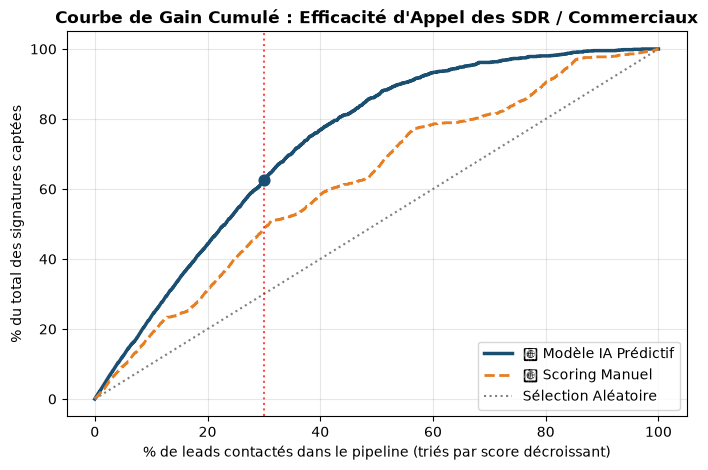

💡 En appelant seulement les 30% des meilleurs leads identifiés par l'IA,
   l'équipe commerciale sécurise 62.5% de la totalité des conversions !


In [22]:
import numpy as np

def calculate_cumulative_gains(y_true, y_scores):
    # Tri décroissant selon le score
    sorted_indices = np.argsort(y_scores)[::-1]
    y_true_sorted = np.array(y_true)[sorted_indices]
    
    # Calcul des pourcentages cumulés
    cum_conversions = np.cumsum(y_true_sorted)
    total_conversions = np.sum(y_true_sorted)
    gain = cum_conversions / total_conversions
    
    percentages = np.linspace(0, 1, len(y_true) + 1)
    gain = np.insert(gain, 0, 0)
    return percentages * 100, gain * 100

pcts, gain_ia = calculate_cumulative_gains(y_test, y_scores_ia)
_, gain_man = calculate_cumulative_gains(y_test, y_scores_manual)

plt.figure(figsize=(8, 5))
plt.plot(pcts, gain_ia, label="🎯 Modèle IA Prédictif", color="#1b4f72", lw=2.5)
plt.plot(pcts, gain_man, label="📝 Scoring Manuel", color="#e67e22", lw=2, linestyle="--")
plt.plot([0, 100], [0, 100], color="grey", linestyle=":", label="Sélection Aléatoire")

# Repère à 30% d'effort commercial
idx_30 = int(len(pcts) * 0.3)
plt.axvline(x=30, color="red", linestyle=":", alpha=0.7)
plt.scatter([30], [gain_ia[idx_30]], color="#1b4f72", s=60, zorder=5)

plt.title("Courbe de Gain Cumulé : Efficacité d'Appel des SDR / Commerciaux", fontsize=12, fontweight="bold")
plt.xlabel("% de leads contactés dans le pipeline (triés par score décroissant)")
plt.ylabel("% du total des signatures captées")
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

print(f"💡 En appelant seulement les 30% des meilleurs leads identifiés par l'IA,")
print(f"   l'équipe commerciale sécurise {gain_ia[idx_30]:.1f}% de la totalité des conversions !")

# PARTIE 5 : EXPORT DES LIVRABLES & SYNCHRONISATION ODOO CRM

Objectif :
1. Mapper les probabilités calculées par l'IA en Étoiles de Priorité Odoo (0 à 3 étoiles).
2. Générer l'explication textuelle du score (Interprétabilité) pour le Chatter.
3. Exporter le 'fichier d'import' officiel (Demandé par le professeur).
4. (Optionnel) Synchronisation automatique via XML-RPC.

In [23]:
# 1. Création du DataFrame de livraison basé sur le jeu de test
df_export_odoo = X_test.copy()

# Probabilité continue calculée par l'IA (en %)
df_export_odoo["probability"] = (y_scores_ia * 100).round(1)

# Attribution dynamique des Étoiles de Priorité (0, 1, 2, ou 3 étoiles)
def map_priority(prob):
    if prob >= 75.0:
        return '3'  # ★★★ Haute priorité (Hot Lead)
    elif prob >= 50.0:
        return '2'  # ★★ Priorité moyenne
    elif prob >= 25.0:
        return '1'  # ★ Basse priorité
    else:
        return '0'  # Lead froid / Nurturing

df_export_odoo["priority"] = df_export_odoo["probability"].apply(map_priority)

# Nom d'opportunité lisible pour le Kanban Odoo
df_export_odoo["name"] = [f"Opportunité Web #{idx}" for idx in df_export_odoo.index]
df_export_odoo["contact_name"] = [f"Prospect #{idx}" for idx in df_export_odoo.index]

# Génération de la note d'explication IA pour le commercial
def generate_ai_reason(row):
    reasons = []
    if row.get("Total Time Spent on Website", 0) > 400:
        reasons.append("Temps sur site élevé (>400s)")
    if row.get("Last Activity") in ["Email Opened", "SMS Sent"]:
        reasons.append(f"Activité récente ({row.get('Last Activity')})")
    if row.get("Lead Source") in ["Google", "Reference"]:
        reasons.append(f"Canal qualifié ({row.get('Lead Source')})")
    
    if not reasons:
        reasons.append("Engagement standard")
    return "⚡ AI Insight: " + " + ".join(reasons)

df_export_odoo["description"] = df_export_odoo.apply(generate_ai_reason, axis=1)

# 2. SÉLECTION STRICTE DES COLONNES POUR L'IMPORT NATIF ODOO
# Ces colonnes correspondent exactement aux champs techniques du modèle 'crm.lead'
odoo_ready_columns = [
    "name",            # Nom de l'opportunité
    "contact_name",    # Nom du contact
    "probability",     # Probabilité de succès (%)
    "priority",        # Étoiles de priorité (0 à 3)
    "description"      # Notes internes / Explication IA
]

fichier_import_final = df_export_odoo[odoo_ready_columns]

# Sauvegarde du Livrable : Fichier d'import demandé par la prof
fichier_import_final.to_csv("fichier_import_odoo.csv", index=False, encoding="utf-8")

print("=" * 60)
print(f"✅ Livrable 'fichier_import_odoo.csv' généré avec succès ({len(fichier_import_final)} lignes) !")
print("=" * 60)
display(fichier_import_final.head(10))

# 3. SAUVEGARDE DU PIPELINE MODÈLE ENTRAÎNÉ (PERSISTANCE PKL)
# Permet à sync_odoo.py et à toute API d'utiliser directement le modèle sans réentraînement
import joblib

# Export du modèle de production
joblib.dump(lead_model, 'lead_scoring_model.pkl')
print(f"💾 Modèle principal 'lead_scoring_model.pkl' exporté avec succès !")

# Export du modèle LightGBM alternatif si disponible
if 'LightGBM' in candidate_models:
    joblib.dump(candidate_models['LightGBM'], 'lead_scoring_lgbm.pkl')
    print("💾 Modèle alternatif 'lead_scoring_lgbm.pkl' exporté avec succès !")


✅ Livrable 'fichier_import_odoo.csv' généré avec succès (2772 lignes) !


,name,contact_name,probability,priority,description
8305,Opportunité Web #8305,Prospect #8305,15.2,0,⚡ AI Insight: Activité récente (Email Opened)
1591,Opportunité Web #1591,Prospect #1591,79.1,3,⚡ AI Insight: Temps sur site élevé (>400s) + A...
8604,Opportunité Web #8604,Prospect #8604,68.1,2,⚡ AI Insight: Activité récente (SMS Sent) + Ca...
1333,Opportunité Web #1333,Prospect #1333,1.5,0,⚡ AI Insight: Temps sur site élevé (>400s)
4260,Opportunité Web #4260,Prospect #4260,2.8,0,⚡ AI Insight: Engagement standard
2357,Opportunité Web #2357,Prospect #2357,96.1,3,⚡ AI Insight: Activité récente (SMS Sent)
1900,Opportunité Web #1900,Prospect #1900,73.5,2,⚡ AI Insight: Temps sur site élevé (>400s) + A...
9077,Opportunité Web #9077,Prospect #9077,30.2,1,⚡ AI Insight: Activité récente (Email Opened)
6302,Opportunité Web #6302,Prospect #6302,81.1,3,⚡ AI Insight: Canal qualifié (Google)
8158,Opportunité Web #8158,Prospect #8158,40.0,1,⚡ AI Insight: Activité récente (Email Opened)


💾 Modèle principal 'lead_scoring_model.pkl' exporté avec succès !
💾 Modèle alternatif 'lead_scoring_lgbm.pkl' exporté avec succès !
